hw7 
==========

In [1]:
import os
import time
from pathlib import Path
from collections import Counter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf



from sklearn.model_selection import train_test_split

from tensorflow.keras import Input, Sequential
from tensorflow.keras.layers import (
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Reproducibility
random_seed = 42
tf.keras.utils.set_random_seed(random_seed)

# Utility
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


print("Visible GPUs:", tf.config.get_visible_devices("GPU"))

Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# premade functions

In [2]:
def plot_learning_curves(history, title="Learning Curves", show=True):

    h = history.history

    best_idx = int(np.argmin(h["val_loss"]))
    best_epoch = best_idx + 1
    epochs = np.arange(1, len(h["loss"]) + 1)

    fig, axs = plt.subplots(
        2, 1, figsize=(8, 7), sharex=True
    )

    # Loss
    axs[0].plot(epochs, h["loss"], label="Training")
    axs[0].plot(epochs, h["val_loss"], label="Validation")
    axs[0].scatter(
        best_epoch, h["val_loss"][best_idx],
        color="red", marker="x", s=70,
        label=f"Best epoch: {best_epoch}"
    )
    axs[0].set_title(f"{title} — Binary Cross-Entropy")
    axs[0].set_ylabel("Loss")
    axs[0].legend()
    axs[0].grid(True, alpha=0.3)

    # Accuracy
    axs[1].plot(epochs, h["accuracy"], label="Training")
    axs[1].plot(epochs, h["val_accuracy"], label="Validation")
    axs[1].scatter(
        best_epoch, h["val_accuracy"][best_idx],
        color="red", marker="x", s=70,
        label="Accuracy at best epoch"
    )
    axs[1].set_title("Accuracy")
    axs[1].set_xlabel("Epoch")
    axs[1].set_ylabel("Accuracy")
    axs[1].set_ylim(0, 1.05)
    axs[1].legend()
    axs[1].grid(True, alpha=0.3)

    plt.tight_layout()

    if show:
        plt.show()
    else:
        plt.close(fig)

    return best_idx


In [3]:
def train_and_validate(
    model,
    X_train, y_train,
    X_val, y_val,
    title="Learning Curves",
    epochs=200,
    optimizer="Adam",
    lr_schedule=1e-3,
    clipnorm=None,
    batch_size=128,
    loss="binary_crossentropy",
    metrics=None,
    use_early_stopping=True,
    patience=10,
    min_delta=0.0001,
    callbacks=None,
    verbose=0,
    plot=True
):

    if metrics is None:
        metrics = ["accuracy"]

    if callbacks is None:
        callbacks = []

    print(f"\n{title}\n")

    if optimizer == "Adam":
        opt = Adam(
            learning_rate=lr_schedule,
            clipnorm=clipnorm
        )
    else:
        opt = optimizer

    model.compile(
        optimizer=opt,
        loss=loss,
        metrics=metrics
    )

    cbs = list(callbacks)

    if use_early_stopping:
        cbs.insert(0, EarlyStopping(
            monitor="val_loss",
            patience=patience,
            min_delta=min_delta,
            restore_best_weights=True,
            verbose=verbose
        ))

    start = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=cbs,
        verbose=verbose
    )

    elapsed = time.time() - start

    h = history.history
    best_idx = int(np.argmin(h["val_loss"]))
    best_epoch = best_idx + 1
    num_epochs = len(h["loss"])

    best_val_loss = float(h["val_loss"][best_idx])
    best_val_acc = float(h["val_accuracy"][best_idx])
    train_acc_at_best = float(h["accuracy"][best_idx])

    if plot:
        plot_learning_curves(history, title=title)

    print(f"Epochs Trained:                {num_epochs}")
    print(f"Best Epoch:                    {best_epoch}")
    print(f"Training Accuracy @ Best:      {train_acc_at_best:.4f}")
    print(f"Validation Loss @ Best:        {best_val_loss:.4f}")
    print(f"Validation Accuracy @ Best:    {best_val_acc:.4f}")
    print(f"Execution Time:                {format_hms(elapsed)}")

    return {
            "title": title,
            "best_epoch": best_epoch,
            "epochs_trained": num_epochs,
            "Val Loss @ Best": best_val_loss,
            "Val Acc @ Best": best_val_acc,
            "Execution Seconds": elapsed
        }


In [4]:
def prepare_sequences(raw_sequences, vocabulary_size, max_length):
    """Apply vocabulary cap, then pad/truncate sequences."""

    capped = [
        [token if token < vocabulary_size else 2
         for token in review]
        for review in raw_sequences
    ]

    return pad_sequences(
        capped,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

---

# p0

## dataset

In [5]:
training_vocabulary_size = 50_000       # <-----
max_text_length          = 500          # <-----
DATA_FRACTION            = 0.15         # <----- 1.0 for final submission

assert 0 < DATA_FRACTION <= 1.0

In [6]:

# ------------------------------------------------------------
# 1. Load all reviews without restricting the vocabulary
# ------------------------------------------------------------

(X_tr, y_tr), (X_te, y_te) = imdb.load_data()

X = np.concatenate([X_tr, X_te], axis=0)
y = np.concatenate([y_tr, y_te], axis=0)

# ------------------------------------------------------------
# 2. Stratified 80/10/10 train/validation/test split
# ------------------------------------------------------------

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=random_seed,
    stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=random_seed,
    stratify=y_temp
)

# ------------------------------------------------------------
# 3. Training-data throttle
#    Keep validation and test sets unchanged
# ------------------------------------------------------------

if DATA_FRACTION < 1.0:
    X_train_raw, _, y_train, _ = train_test_split(
        X_train_raw,
        y_train,
        train_size=DATA_FRACTION,
        random_state=random_seed,
        stratify=y_train
    )

print(f"DATA_FRACTION:      {DATA_FRACTION}")
print(f"Training reviews:   {len(X_train_raw):,}")
print(f"Validation reviews: {len(X_val_raw):,}")
print(f"Test reviews:       {len(X_test_raw):,}")

# ------------------------------------------------------------
# 4. Apply vocabulary restriction and pad/truncate sequences
#    Preserve the raw sequences for later experiments
# ------------------------------------------------------------

X_train = prepare_sequences(
    X_train_raw, training_vocabulary_size, max_text_length
)

X_val = prepare_sequences(
    X_val_raw, training_vocabulary_size, max_text_length
)

X_test = prepare_sequences(
    X_test_raw, training_vocabulary_size, max_text_length
)

print()
print("Training:  ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)

DATA_FRACTION:      0.15
Training reviews:   6,000
Validation reviews: 5,000
Test reviews:       5,000

Training:   (6000, 500)
Validation: (5000, 500)
Test:       (5000, 500)


## review

In [7]:

# # ------------------------------------------------------------
# # 1. Global vocabulary statistics
# # ------------------------------------------------------------

# word_index = imdb.get_word_index()
# total_unique_words_corpus = len(word_index)

# print(f"Total unique words in Keras IMDB word_index "
#       f"(corpus-wide): {total_unique_words_corpus:,}")

# # ------------------------------------------------------------
# # 2. Review length statistics
# # ------------------------------------------------------------

# lengths = np.fromiter(
#     (len(review) for review in X_train_raw),
#     dtype=np.int32
# )

# print(f"\nNumber of training reviews: {len(lengths):,}")
# print(f"Max length: {lengths.max():,} tokens")
# print(f"Mean length: {lengths.mean():.1f} tokens")
# print(f"Median length: {np.median(lengths):.0f} tokens")

# for q in (90, 95, 99):
#     print(f"{q}th percentile: "
#           f"{int(np.percentile(lengths, q))} tokens")

# plt.figure(figsize=(8, 5))
# plt.hist(lengths, bins=100, edgecolor="blue")
# plt.title("Histogram of IMDB Review Lengths (Training Set)")
# plt.xlabel("Tokens per review")
# plt.ylabel("Frequency")
# plt.grid(axis="y", alpha=0.3)
# plt.show()


In [8]:

# # ------------------------------------------------------------
# # 3. Token frequency counts (training data only)
# #
# # IMDB token IDs:
# #   0 = PAD
# #   1 = START
# #   2 = OOV
# #   3 = UNUSED
# #   4+ = actual words
# # ------------------------------------------------------------

# train_counts = Counter(
#     token
#     for review in X_train_raw
#     for token in review
#     if token >= 4
# )

# total_tokens_train_words = sum(train_counts.values())
# num_unique_words_train = len(train_counts)

# print(f"\nUnique word types in TRAIN: "
#       f"{num_unique_words_train:,}")
# print(f"Total word tokens in TRAIN: "
#       f"{total_tokens_train_words:,}")

# # ------------------------------------------------------------
# # 4. Calculate vocabulary coverage
# #
# # Keras assigns lower token IDs to more frequent words
# # in the original IMDB vocabulary.
# #
# # A vocabulary cap K retains word IDs below K.
# # All remaining word IDs become OOV.
# # ------------------------------------------------------------

# def coverage_for_cap(num_words_cap):

#     kept_types = sum(
#         token < num_words_cap
#         for token in train_counts
#     )

#     kept_tokens = sum(
#         count
#         for token, count in train_counts.items()
#         if token < num_words_cap
#     )

#     oov_tokens = total_tokens_train_words - kept_tokens

#     coverage = kept_tokens / total_tokens_train_words
#     oov_share = oov_tokens / total_tokens_train_words

#     return {
#         "cap": num_words_cap,
#         "kept_tokens": kept_tokens,
#         "kept_types": kept_types,
#         "coverage": coverage,
#         "oov_share": oov_share
#     }

# # ------------------------------------------------------------
# # 5. Vocabulary coverage table
# # ------------------------------------------------------------

# candidate_caps = [
#     2_000, 5_000, 10_000, 20_000,
#     30_000, 50_000, 70_000, 88_588
# ]

# rows = [coverage_for_cap(k) for k in candidate_caps]

# print("\nCoverage metrics by candidate vocabulary size "
#       "(TRAIN split):")

# for r in rows:
#     print(
#         f"training_vocabulary_size={r['cap']:>7,} | "
#         f"coverage={r['coverage']*100:6.2f}% | "
#         f"OOV={r['oov_share']*100:6.2f}% | "
#         f"types kept={r['kept_types']:>7,} | "
#         f"tokens kept={r['kept_tokens']:>10,}"
#     )

# # ------------------------------------------------------------
# # 6. Vocabulary coverage plot
# # ------------------------------------------------------------

# plt.figure(figsize=(8, 5))

# plt.plot(
#     candidate_caps,
#     [r["coverage"] for r in rows],
#     marker="o"
# )

# plt.xlabel("training_vocabulary_size (num_words)")
# plt.ylabel("Token coverage on TRAIN (fraction)")
# plt.title("Token Coverage vs. Vocabulary Size (TRAIN only)")
# plt.grid(True, linestyle=":", alpha=0.6)
# plt.ylim(0.75, 1.02)
# plt.show()


    ---

## GloVe

In [9]:
embedding_dimension = 100                 # <-----

word_index = imdb.get_word_index()

# GloVe 6B provides 50, 100, 200, and 300 dimensions
assert embedding_dimension in (50, 100, 200, 300)

glove_path = Path(
    f"../glove.6B/glove.6B.{embedding_dimension}d.txt"
)

if not glove_path.exists():
    raise FileNotFoundError(f"GloVe file not found: {glove_path}")

In [13]:
embeddings_index = {}

with glove_path.open(encoding="utf8") as f:
    for line in f:
        word, *vec = line.split()
        embeddings_index[word] = np.asarray(
            vec, dtype="float32"
        )

print(f"Loaded {len(embeddings_index):,} GloVe vectors "
      f"of dimension {embedding_dimension}")

# ------------------------------------------------------------
# Construct embedding matrix
# ------------------------------------------------------------

embedding_matrix = np.zeros(
    (training_vocabulary_size, embedding_dimension),
    dtype="float32"
)

matched = 0
total_words = 0

for word, raw_idx in word_index.items():

    idx = raw_idx + 3  # Keras IMDB reserved-token offset

    if idx < training_vocabulary_size:
        total_words += 1

        vec = embeddings_index.get(word)

        if vec is not None:
            embedding_matrix[idx] = vec
            matched += 1

# ------------------------------------------------------------
# Report embedding coverage
# ------------------------------------------------------------

print(f"Embedding matrix shape: {embedding_matrix.shape}")
print(f"Vocabulary words:       {total_words:,}")
print(f"Words found in GloVe:   {matched:,}")
print(f"Words missing in GloVe: {total_words - matched:,}")
print(f"GloVe word coverage:    {matched / total_words:.2%}")

Loaded 400,000 GloVe vectors of dimension 100
Embedding matrix shape: (50000, 100)
Vocabulary words:       49,996
Words found in GloVe:   42,330
Words missing in GloVe: 7,666
GloVe word coverage:    84.67%


## base model

In [14]:

# # # ==================================================
# # # Baseline: Frozen GloVe Embeddings
# # # ==================================================

# model_baseline_frozen = Sequential([
#     Input(shape=(max_text_length,), dtype="int32"),

#     Embedding(
#         input_dim=training_vocabulary_size,
#         output_dim=embedding_dimension,
#         weights=[embedding_matrix],
#         mask_zero=True,          # Exclude padding from pooling
#         trainable=False          # Freeze pretrained embeddings
#     ),

#     GlobalAveragePooling1D(),    # Average word embeddings
#     Dense(1, activation="sigmoid")
# ])

# frozen_results = train_and_validate(
#     model_baseline_frozen,
#     X_train, y_train,
#     X_val, y_val,
#     epochs = 100, 
#     lr_schedule=1e-2,
#     title="Baseline — Frozen GloVe"
# )


---
# p1

In [40]:
def build_embedding_matrix(
    embeddings_index,
    word_index,
    training_vocabulary_size,
    embedding_dimension,
):

    embedding_matrix = np.zeros(
        (training_vocabulary_size, embedding_dimension),
        dtype="float32"
    )

    matched = 0
    total_words = 0

    for word, raw_idx in word_index.items():

        idx = raw_idx + 3  ## - Keras IMDB reserved-token offset

        if idx < training_vocabulary_size:
            total_words += 1

            vec = embeddings_index.get(word)

            if vec is not None:
                embedding_matrix[idx] = vec
                matched += 1

    print(f"Matched {matched:,} of {total_words:,} words ({matched / total_words:.1%})")

    return embedding_matrix

In [41]:
def p1_model_quick_function(
    t =         training_vocabulary_size,
    em =        embedding_matrix,
    ed =        embedding_dimension,
    maxtext_l = max_text_length,
    embedding_trainable=    False,
    hidden_dense=[],
    dense_units=    0,
    dropout=    0.0,
    l2_reg=     None,
):

    reg = tf.keras.regularizers.L2(l2_reg) if l2_reg else None

    layer_list = [
        Input(shape=(maxtext_l,), dtype="int32"),

        Embedding(
            input_dim=  t,
            output_dim= ed,
            weights=    [em],
            mask_zero=  True,
            trainable=  embedding_trainable
        ),

        GlobalAveragePooling1D(),
    ]

    ## - optional hidden dense layers
    for units in hidden_dense:
        layer_list += [
            Dense(
                units,
                activation="relu",
                kernel_regularizer=reg
            )
        ]

        if dropout > 0:
            layer_list += [
                Dropout(dropout)
            ]

    ## - optional dense layer before output
    if dense_units > 0:
        layer_list += [
            Dense(
                dense_units,
                activation="relu",
                kernel_regularizer=reg
            )
        ]

        if dropout > 0:
            layer_list += [
                Dropout(dropout)
            ]

    layer_list += [
        Dense(1, activation="sigmoid")
    ]

    model = Sequential(layer_list)

    return model



In [16]:
# p0_baseline_model = p1_model_quick_function()   
# p0_result = train_and_validate(
#         p0_baseline_model,

#         X_train, y_train,
#         X_val, y_val,
#         title=          "p0 - baseline - frozen GloVe",
#         epochs=         200,
#         optimizer=      "Adam",
#         lr_schedule=     1e-3,
#         clipnorm=       None,
#         batch_size=     128,
#         loss=           "binary_crossentropy",
#         metrics=         None,
#         use_early_stopping=True,
#         patience=        10,
#         min_delta=      0.0001,
#         callbacks=      None,
#         verbose=        0,
#         plot=           True
# )

In [17]:
# p0_baseline_model2 = p1_model()   
# p0_result = train_and_validate(
#         p0_baseline_model2,

#         X_train, y_train,
#         X_val, y_val,
#         title=          "p0 - baseline - frozen GloVe",
#         epochs=         200,
#         optimizer=      "Adam",
#         lr_schedule=     1e-4,  ####____◄ edit
#         clipnorm=       None,
#         batch_size=     128,
#         loss=           "binary_crossentropy",
#         metrics=         None,
#         use_early_stopping=True,
#         patience=        10,
#         min_delta=      0.0001,
#         callbacks=      None,
#         verbose=        0,
#         plot=           True
# )

## experiment

In [18]:
## - shared model inputs and pretrained embedding settings
nlp_model_config_common = dict(
    t=          training_vocabulary_size,
    # em=         embedding_matrix,
    # ed=         embedding_dimension,
    # maxtext_l=  max_text_length
)

## - shared training defaults; individual experiments can override these
nlp_train_config_common = dict(
    epochs=             200,
    # lr_schedule=        1e-2,
    # batch_size=         128,
    # patience=           10
)


nlp_train_option_keys = [
    "lr_schedule",
    "epochs",
    "batch_size",
    "patience"
]

In [26]:
p1_experiment_configs  = {
    # "p0 - baseline - frozen GloVe" : dict(),   
    # "p1 - baseline unfrozen"    : dict(embedding_trainable = True),
    "p0 - LR 1e-4"              : dict(lr_schedule = 1e-4),
    # "p1 - extra dense layer"    : dict(embedding_trainable = True, hidden_dense = [64]),
    # "p1 - l2 regularization"    : dict(embedding_trainable = True, l2_regularization = 1e-4),
    # "p1 - dropout layer"        : dict(embedding_trainable = True, dropout = 0.3),
}





p0 - LR 1e-4



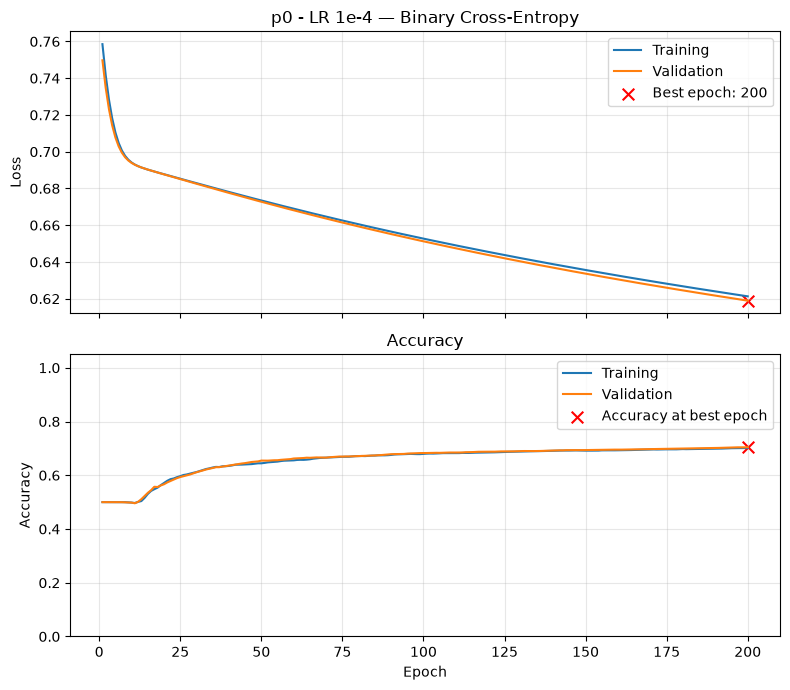

Epochs Trained:                200
Best Epoch:                    200
Training Accuracy @ Best:      0.7015
Validation Loss @ Best:        0.6189
Validation Accuracy @ Best:    0.7046
Execution Time:                00:01:22


In [27]:
## - dictionaries to store experiment outputs
nlp_experiment_results = {}
nlp_fitted_models = {}
nlp_experiment_result_dfs = {}
# nlp_experiment_history_dfs = {}



for nlp_experiment_title, nlp_experiment_cfg in p1_experiment_configs.items():

    ## - split experiment settings into model settings and training settings
    nlp_model_cfg = {
        key: value
        for key, value in nlp_experiment_cfg.items()
        if key not in nlp_train_option_keys
    }

    nlp_train_cfg = {
        key: value
        for key, value in nlp_experiment_cfg.items()
        if key in nlp_train_option_keys
    }

    ## - build the model for this experiment
    nlp_model = p1_model_quick_function(
        **{**nlp_model_config_common, **nlp_model_cfg}
    )

    ## - train, validate, plot, and collect summary metrics
    nlp_result = train_and_validate(
        nlp_model,
        X_train, y_train,
        X_val, y_val,
        title=nlp_experiment_title,
        **nlp_train_config_common,
        **nlp_train_cfg
    )

    ## - save summary result and fitted model under the experiment title
    nlp_experiment_results[nlp_experiment_title] = nlp_result
    nlp_fitted_models[nlp_experiment_title] = nlp_model

    nlp_experiment_result_dfs[nlp_experiment_title] = (
        pd.DataFrame(
            [nlp_result],
            index=[nlp_experiment_title]
        )
    )

    # ## - one epoch-level DataFrame for this specific experiment
    # nlp_experiment_history_dfs[nlp_experiment_title] = (
    #     pd.DataFrame(nlp_model.history.history)
    #     .assign(
    #         epoch = lambda x: np.arange(1, len(x) + 1),
    #         experiment = nlp_experiment_title
    #     )
    # )




In [28]:
nlp_experiment_results 


{'p0 - LR 1e-4': {'title': 'p0 - LR 1e-4',
  'best_epoch': 200,
  'epochs_trained': 200,
  'Val Loss @ Best': 0.6189330816268921,
  'Val Acc @ Best': 0.7045999765396118,
  'Execution Seconds': 82.45047855377197}}

In [34]:
nlp_all_results_df = (
    pd.DataFrame(nlp_experiment_results).T.reset_index(drop=True)
)

nlp_all_results_df

,title,best_epoch,epochs_trained,Val Loss @ Best,Val Acc @ Best,Execution Seconds
0,p0 - LR 1e-4,200,200,0.618933,0.7046,82.450479


In [61]:
a1a = nlp_all_results_df.query("title == 'p0 - LR 1e-4'")['Val Loss @ Best'].iloc[0]
print(f"{a1a: .4f}")

 0.6189


In [67]:
nlp_all_results_df.sort_values("Val Acc @ Best", ascending=False)

,title,best_epoch,epochs_trained,Val Loss @ Best,Val Acc @ Best,Execution Seconds,vocab_size,embed_dim,max_len,lr
p3a - ed 300,p3a - ed 300,47,56,0.307804,0.8736,43.628665,50000.0,300.0,500.0,0.0001
"p2 - vocab 10k, dim 100, len 500","p2 - vocab 10k, dim 100, len 500",89,98,0.312911,0.8682,49.991196,10000.0,100.0,500.0,0.0001
0,p0 - LR 1e-4,200,200,0.618933,0.7046,82.450479,NaN,NaN,NaN,NaN


In [68]:
(
    nlp_all_results_df
    .query("title.str.contains('p2', case=False, na=False)")
    .sort_values("Val Acc @ Best", ascending=False)
    ['vocab_size'].iloc[0]
)

np.float64(10000.0)

---

# p2

In [46]:
from tensorflow.keras.preprocessing.sequence import pad_sequences


In [47]:
## - NEW: matrix builder (same logic and names as your original loop)
def p2_build_embedding_matrix(
    embeddings_index,
    word_index,
    training_vocabulary_size,
    embedding_dimension,
):

    embedding_matrix = np.zeros(
        (training_vocabulary_size, embedding_dimension),
        dtype="float32"
    )

    matched = 0
    total_words = 0

    for word, raw_idx in word_index.items():

        idx = raw_idx + 3  ## - Keras IMDB reserved-token offset

        if idx < training_vocabulary_size:
            total_words += 1

            vec = embeddings_index.get(word)

            if vec is not None:
                embedding_matrix[idx] = vec
                matched += 1

    print(f"Matched {matched:,} of {total_words:,} words ({matched / total_words:.1%})")

    return embedding_matrix


## - NEW: model builder; builds its own embedding_matrix from the vocab size
def p2_model_w_options(
    embeddings_index,
    word_index,
    training_vocabulary_size,
    embedding_dimension,
    max_text_length,
    embedding_trainable=False,
    hidden_dense=[],
    dense_units=0,
    dropout=0.0,
    l2_reg=None,
):

    reg = regularizers.L2(l2_reg) if l2_reg else None

    embedding_matrix = p2_build_embedding_matrix(
        embeddings_index,
        word_index,
        training_vocabulary_size,
        embedding_dimension
    )

    layer_list = [
        Input(shape=(max_text_length,), dtype="int32"),

        Embedding(
            input_dim=training_vocabulary_size,
            output_dim=embedding_dimension,
            weights=[embedding_matrix],
            mask_zero=True,
            trainable=embedding_trainable
        ),

        GlobalAveragePooling1D(),
    ]

    for units in hidden_dense:
        layer_list += [Dense(units, activation="relu", kernel_regularizer=reg)]
        if dropout > 0:
            layer_list += [Dropout(dropout)]

    if dense_units > 0:
        layer_list += [Dense(dense_units, activation="relu", kernel_regularizer=reg)]
        if dropout > 0:
            layer_list += [Dropout(dropout)]

    layer_list += [Dense(1, activation="sigmoid")]

    return Sequential(layer_list)


## - NEW: clip words outside the vocab and set sequence length for this experiment
def p2_prepare_inputs(X, training_vocabulary_size, max_text_length, oov_index=2):

    X_prepared = pad_sequences(
        X,
        maxlen=max_text_length   ## - default: pre-padding, keeps the LAST max_text_length tokens
    )

    return np.where(X_prepared < training_vocabulary_size, X_prepared, oov_index)

Matched 9,793 of 9,996 words (98.0%)

p2 - vocab 10k, dim 100, len 500



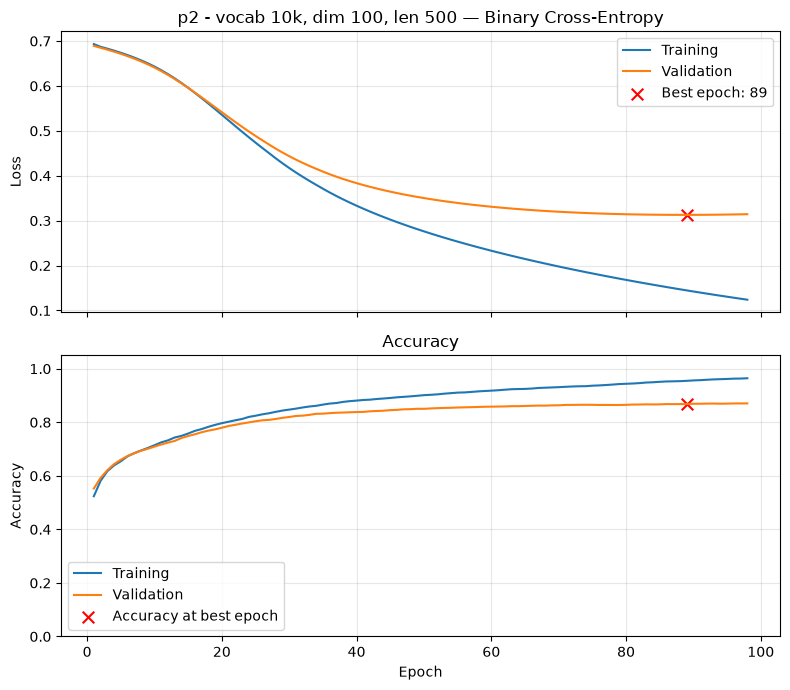

Epochs Trained:                98
Best Epoch:                    89
Training Accuracy @ Best:      0.9548
Validation Loss @ Best:        0.3129
Validation Accuracy @ Best:    0.8682
Execution Time:                00:00:49


,title,best_epoch,epochs_trained,Val Loss @ Best,Val Acc @ Best,Execution Seconds,vocab_size,embed_dim,max_len,lr
"p2 - vocab 10k, dim 100, len 500","p2 - vocab 10k, dim 100, len 500",89,98,0.312911,0.8682,49.991196,10000.0,100.0,500.0,0.0001
0,p0 - LR 1e-4,200,200,0.618933,0.7046,82.450479,NaN,NaN,NaN,NaN


In [48]:
## - shared model settings; base values for the three size parameters
p2_model_config_common = dict(
    embedding_trainable=True,
    hidden_dense=[64],
    embeddings_index=embeddings_index,
    word_index=word_index,
    training_vocabulary_size=50_000,
    embedding_dimension=100,
    max_text_length=500,
)

p2_train_config_common = dict(
    lr_schedule=1e-4,
)

## - keys that belong to train_and_validate
p2_train_option_keys = ["lr_schedule", "epochs", "batch_size", "patience"]

## - experiments override only what differs from the base values
p2_experiment_configs = {
    "p2 - vocab 10k, dim 100, len 500": dict(training_vocabulary_size=10_000),
    # "p2 - vocab 20k, dim 100, len 500": dict(training_vocabulary_size=20_000),
    # "p2 - vocab 50k, dim 100, len 300": dict(
    #     max_text_length=300
    # ),
}


## - initialize once; re-running the loop will NOT erase earlier rows
if "nlp_all_results_df" not in globals():
    nlp_all_results_df = pd.DataFrame()

for nlp_experiment_title, nlp_experiment_cfg in p2_experiment_configs.items():

    ## - split experiment settings into model settings and training settings
    p2_model_cfg = {
        key: value
        for key, value in nlp_experiment_cfg.items()
        if key not in p2_train_option_keys
    }

    p2_train_cfg = {
        key: value
        for key, value in nlp_experiment_cfg.items()
        if key in p2_train_option_keys
    }

    ## - final model settings = common + experiment overrides
    p2_model_cfg_final = {**p2_model_config_common, **p2_model_cfg}

    ## - clip data to this experiment's vocab size and text length
    X_train_p2 = p2_prepare_inputs(
        X_train,
        p2_model_cfg_final["training_vocabulary_size"],
        p2_model_cfg_final["max_text_length"]
    )
    X_val_p2 = p2_prepare_inputs(
        X_val,
        p2_model_cfg_final["training_vocabulary_size"],
        p2_model_cfg_final["max_text_length"]
    )

    nlp_model = p2_model_w_options(**p2_model_cfg_final)

    nlp_result = train_and_validate(
        nlp_model,
        X_train_p2, y_train,
        X_val_p2, y_val,
        title=nlp_experiment_title,
        **{**p2_train_config_common, **p2_train_cfg}
    )

    ## - keep dict storage (results, models, full histories)
    nlp_experiment_results[nlp_experiment_title] = nlp_result
    nlp_fitted_models[nlp_experiment_title] = nlp_model
    nlp_experiment_history_dfs[nlp_experiment_title] = (
        pd.DataFrame(nlp_model.history.history)
        .assign(
            epoch = lambda x: np.arange(1, len(x) + 1)
            , experiment = nlp_experiment_title
        )
    )

    ## - NEW: append this run to the combined results table (latest run wins on duplicate titles)
    nlp_all_results_df = (
        pd.concat([
            nlp_all_results_df
            , pd.DataFrame([nlp_result], index=[nlp_experiment_title])
            .assign(
                vocab_size = p2_model_cfg_final["training_vocabulary_size"]
                , embed_dim = p2_model_cfg_final["embedding_dimension"]
                , max_len = p2_model_cfg_final["max_text_length"]
                , lr = {**p2_train_config_common, **p2_train_cfg}["lr_schedule"]
            )
        ])
        .loc[lambda x: ~x.index.duplicated(keep="last")]
    )

nlp_all_results_df.sort_values("Val Loss @ Best")

In [49]:
nlp_all_results_df.drop

,title,best_epoch,epochs_trained,Val Loss @ Best,Val Acc @ Best,Execution Seconds,vocab_size,embed_dim,max_len,lr
0,p0 - LR 1e-4,200,200,0.618933,0.7046,82.450479,NaN,NaN,NaN,NaN
"p2 - vocab 10k, dim 100, len 500","p2 - vocab 10k, dim 100, len 500",89,98,0.312911,0.8682,49.991196,10000.0,100.0,500.0,0.0001


--

# p3

In [51]:
embedding_dimension2 = 300                 # <-----

glove_path = Path(
    f"../glove.6B/glove.6B.{embedding_dimension2}d.txt"
)

embeddings_index = {}

with glove_path.open(encoding="utf8") as f:
    for line in f:
        word, *vec = line.split()
        embeddings_index[word] = np.asarray(
            vec, dtype="float32"
        )

Matched 42,330 of 49,996 words (84.7%)

p3a - ed 300



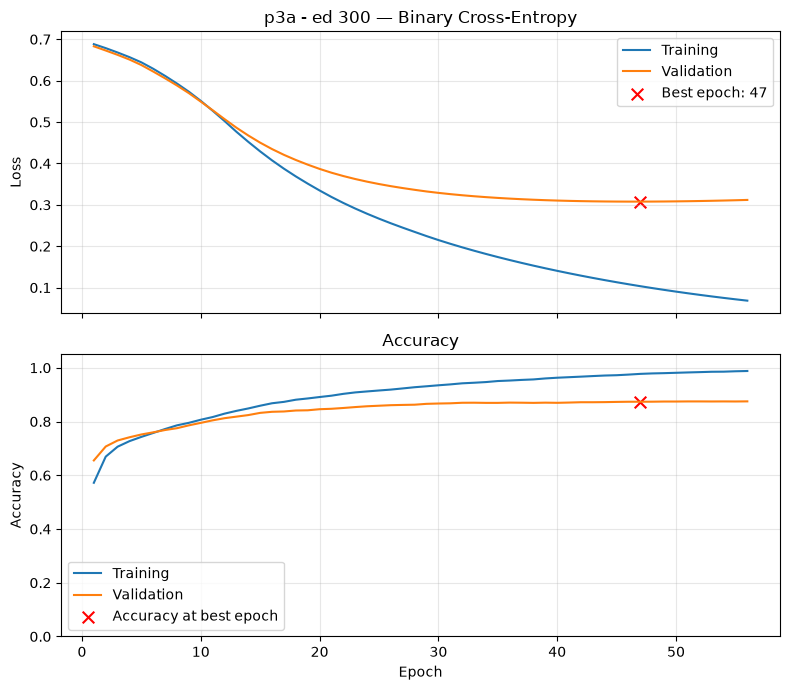

Epochs Trained:                56
Best Epoch:                    47
Training Accuracy @ Best:      0.9773
Validation Loss @ Best:        0.3078
Validation Accuracy @ Best:    0.8736
Execution Time:                00:00:43


,title,best_epoch,epochs_trained,Val Loss @ Best,Val Acc @ Best,Execution Seconds,vocab_size,embed_dim,max_len,lr
p3a - ed 300,p3a - ed 300,47,56,0.307804,0.8736,43.628665,50000.0,300.0,500.0,0.0001
"p2 - vocab 10k, dim 100, len 500","p2 - vocab 10k, dim 100, len 500",89,98,0.312911,0.8682,49.991196,10000.0,100.0,500.0,0.0001
0,p0 - LR 1e-4,200,200,0.618933,0.7046,82.450479,NaN,NaN,NaN,NaN


In [53]:
## - shared model settings; base values for the three size parameters
p3_model_config_common = dict(
    embedding_trainable=True,
    hidden_dense=[64],
    embeddings_index=embeddings_index,
    word_index=word_index,
    training_vocabulary_size=50_000,
    embedding_dimension=embedding_dimension2,
    max_text_length=500,
)

p3_train_config_common = dict(
    lr_schedule=1e-4,
)

p3_train_option_keys = ["lr_schedule", "epochs", "batch_size", "patience"]



#### ----------------------------------------------------- ####
p3_experiment_configs = {
    "p3a - ed 300":     dict(training_vocabulary_size=50_000),
    # "p2 - vocab 20k, dim 100, len 500": dict(training_vocabulary_size=20_000),
    # "p2 - vocab 50k, dim 100, len 300": dict(
    #     max_text_length=300
    # ),
}



for nlp_experiment_title, nlp_experiment_cfg in p3_experiment_configs.items():

    ## - split experiment settings into model settings and training settings
    p3_model_cfg = {
        key: value
        for key, value in nlp_experiment_cfg.items()
        if key not in p3_train_option_keys
    }

    p3_train_cfg = {
        key: value
        for key, value in nlp_experiment_cfg.items()
        if key in p3_train_option_keys
    }

    ## - final model settings = common + experiment overrides
    p3_model_cfg_final = {**p3_model_config_common, **p3_model_cfg}

    ## - clip data to this experiment's vocab size and text length
    X_train_p2 = p2_prepare_inputs(
        X_train,
        p3_model_cfg_final["training_vocabulary_size"],
        p3_model_cfg_final["max_text_length"]
    )
    X_val_p2 = p2_prepare_inputs(
        X_val,
        p3_model_cfg_final["training_vocabulary_size"],
        p3_model_cfg_final["max_text_length"]
    )

    nlp_model = p2_model_w_options(**p3_model_cfg_final)

    nlp_result = train_and_validate(
        nlp_model,
        X_train_p2, y_train,
        X_val_p2, y_val,
        title=nlp_experiment_title,
        **{**p3_train_config_common, **p3_train_cfg}
    )

    ## - keep dict storage (results, models, full histories)
    nlp_experiment_results[nlp_experiment_title] = nlp_result
    nlp_fitted_models[nlp_experiment_title] = nlp_model
    nlp_experiment_history_dfs[nlp_experiment_title] = (
        pd.DataFrame(nlp_model.history.history)
        .assign(
            epoch = lambda x: np.arange(1, len(x) + 1)
            , experiment = nlp_experiment_title
        )
    )

    ## - NEW: append this run to the combined results table (latest run wins on duplicate titles)
    nlp_all_results_df = (
        pd.concat([
            nlp_all_results_df
            , pd.DataFrame([nlp_result], index=[nlp_experiment_title])
            .assign(
                vocab_size = p3_model_cfg_final["training_vocabulary_size"]
                , embed_dim = p3_model_cfg_final["embedding_dimension"]
                , max_len = p3_model_cfg_final["max_text_length"]
                , lr = {**p3_train_config_common, **p3_train_cfg}["lr_schedule"]
            )
        ])
        .loc[lambda x: ~x.index.duplicated(keep="last")]
    )

nlp_all_results_df.sort_values("Val Loss @ Best")

---
# end